# Transfer learning

In [1]:
# ===== Setup & imports =====
!pip install -q timm huggingface_hub

# Standard library
import shutil
import urllib.request
from pathlib import Path
from collections import Counter

# Data & plotting
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# PyTorch & pretrained models
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# Metrics (accuracy, F1, confusion matrix)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Hugging Face download + Colab file download
from huggingface_hub import snapshot_download
from google.colab import files

# Device (separate variable: don't overwrite torch.device like in the lesson notebook)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [ ]:
# dataset folder name -> our class name
mapping = {
    "plov":           "plov",
    "samsa":          "somsa",
    "manty":          "manti",
    "lagman-fried":   "lagman",
    "lagman-w-soup":  "lagman",
    "lagman-wo-soup": "lagman",
}

# 1) Download ONLY these class folders (not all 42)
local = snapshot_download(
    "issai/Central_Asian_Food_Dataset",
    repo_type="dataset",
    allow_patterns=[f"*/{n}/*" for n in mapping],
    local_dir="cafd",
)
root = Path(local)
print("Split folders:", [p.name for p in root.iterdir() if p.is_dir()])

# 2) Arrange into my_data/<split>/<class>/
shutil.rmtree("my_data", ignore_errors=True)
for split_dir in root.iterdir():
    if not split_dir.is_dir() or split_dir.name.startswith("."):
        continue
    counts = Counter()
    for ds_name, cls in mapping.items():
        src = split_dir / ds_name
        if not src.exists():
            continue
        dst = Path("my_data") / split_dir.name / cls
        dst.mkdir(parents=True, exist_ok=True)
        for f in src.iterdir():
            shutil.copy(f, dst / f"{ds_name}_{f.name}")
            counts[cls] += 1
    print(split_dir.name, dict(counts))

# 3) Zip and download to your computer
shutil.make_archive("uzbek_dishes", "zip", "my_data")
print("Zip size (MB):", round(Path("uzbek_dishes.zip").stat().st_size / 1e6, 1))
files.download("uzbek_dishes.zip")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2780 files:   0%|          | 0/2780 [00:00<?, ?it/s]

Split folders: ['.cache', 'test', 'train', 'val', '__MACOSX']
test {'plov': 102, 'somsa': 107, 'manti': 64, 'lagman': 137}
train {'plov': 476, 'somsa': 529, 'manti': 294, 'lagman': 639}
val {'plov': 90, 'somsa': 130, 'manti': 65, 'lagman': 133}
__MACOSX {}
Zip size (MB): 233.4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from google.colab import drive
drive.mount("/content/drive")

!ls -lh /content/drive/MyDrive/uzbek_dishes.zip
!unzip -q -o /content/drive/MyDrive/uzbek_dishes.zip -d my_data
!ls my_data my_data/train

Mounted at /content/drive
-rw------- 1 root root 223M Nov  2 14:39 /content/drive/MyDrive/uzbek_dishes.zip
my_data:
test  train  val

my_data/train:
lagman	manti  plov  somsa


## Step 2

In [3]:
root = Path("my_data")
classes = sorted(p.name for p in (root / "train").iterdir() if p.is_dir())
print("Classes:", classes)

IMG = 224   # lesson tip: 160–224 px

def load(split):
    X, y, bad = [], [], 0
    for c, name in enumerate(classes):
        for f in sorted((root / split / name).iterdir()):
            if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            try:
                img = Image.open(f).convert("RGB").resize((IMG, IMG))
            except Exception:
                bad += 1
                continue
            X.append(np.asarray(img))
            y.append(c)
    X = torch.tensor(np.stack(X)).permute(0, 3, 1, 2)   # (N, 3, H, W)
    y = torch.tensor(y)
    print(f"{split}: {tuple(X.shape)}  skipped: {bad}")
    return X.to(device), y.to(device)

Xtr, ytr = load("train")
Xva, yva = load("val")
Xte, yte = load("test")

Classes: ['lagman', 'manti', 'plov', 'somsa']
train: (1932, 3, 224, 224)  skipped: 0
val: (415, 3, 224, 224)  skipped: 0
test: (405, 3, 224, 224)  skipped: 0


In [4]:
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.float() / 255 - mean) / std

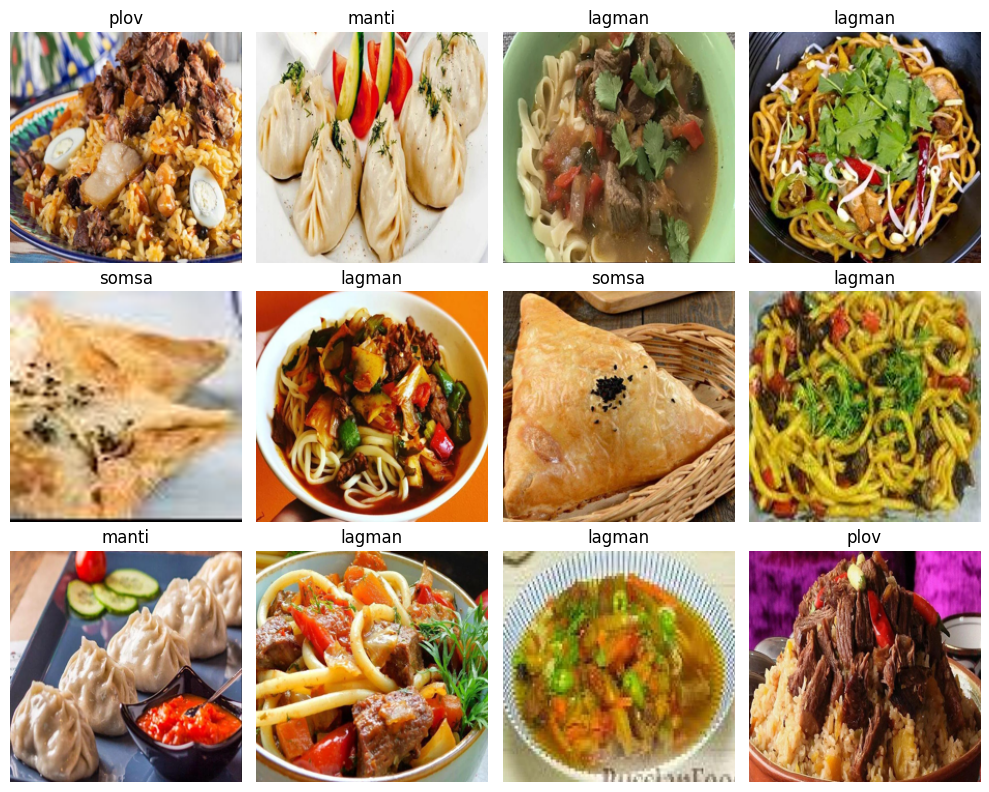

In [5]:
torch.manual_seed(0)
idx = torch.randperm(len(Xtr))[:12]

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, i in zip(axes.flat, idx):
    ax.imshow(Xtr[i].cpu().permute(1, 2, 0))
    ax.set_title(classes[ytr[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 3: Build the model and fine-tune it

In [6]:
torch.manual_seed(0)
model = timm.create_model("resnet18", pretrained=True, num_classes=len(classes)).to(device)
print(model.fc)   # should be Linear(512 -> 4)

def acc(m, X, y):
    m.eval()
    with torch.no_grad():
        out = [m(prep(X[i:i + 100])) for i in range(0, len(X), 100)]
    return (torch.cat(out).argmax(1) == y).float().mean().item()

def train(m, params, epochs=10, lr=3e-4, bs=32):
    opt = torch.optim.Adam(params, lr=lr)
    hist = []
    for e in range(epochs):
        m.train()
        perm = torch.randperm(len(Xtr), device=device)
        total = 0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            xb = Xtr[idx]
            # simple augmentation: random horizontal flip
            flip = torch.rand(len(xb), device=device) < 0.5
            xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
            loss = F.cross_entropy(m(prep(xb)), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        va = acc(m, Xva, yva)
        hist.append(va)
        print(f"epoch {e+1:2d}: train loss {total/len(Xtr):.3f}   val acc {va:.3f}")
    return hist

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Linear(in_features=512, out_features=4, bias=True)


In [7]:
hist = train(model, model.parameters())

epoch  1: train loss 0.788   val acc 0.973
epoch  2: train loss 0.149   val acc 0.986
epoch  3: train loss 0.068   val acc 0.990
epoch  4: train loss 0.050   val acc 0.981
epoch  5: train loss 0.037   val acc 0.993
epoch  6: train loss 0.033   val acc 0.978
epoch  7: train loss 0.026   val acc 0.986
epoch  8: train loss 0.020   val acc 0.990
epoch  9: train loss 0.011   val acc 0.990
epoch 10: train loss 0.008   val acc 0.995


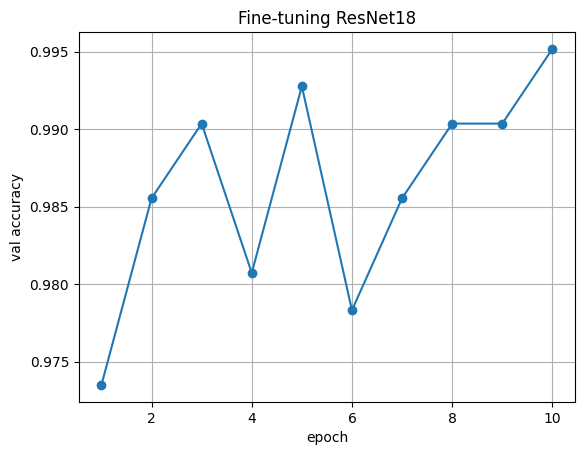

In [8]:
plt.plot(range(1, len(hist) + 1), hist, marker="o")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.title("Fine-tuning ResNet18")
plt.grid(True); plt.show()

## Step 4: F1 score and confusion matrix

===== Validation =====
Accuracy: 0.9952
Macro F1: 0.9942
              precision    recall  f1-score   support

      lagman      0.992     1.000     0.996       131
       manti      0.985     0.985     0.985        65
        plov      1.000     1.000     1.000        89
       somsa      1.000     0.992     0.996       130

    accuracy                          0.995       415
   macro avg      0.994     0.994     0.994       415
weighted avg      0.995     0.995     0.995       415



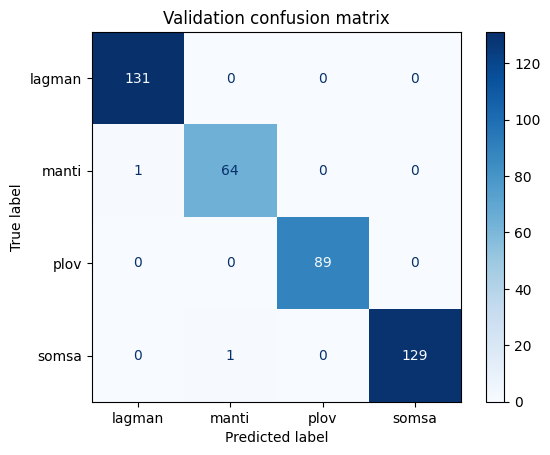

===== Test =====
Accuracy: 0.9926
Macro F1: 0.9925
              precision    recall  f1-score   support

      lagman      0.993     0.993     0.993       135
       manti      1.000     0.984     0.992        63
        plov      0.990     0.990     0.990       101
       somsa      0.991     1.000     0.995       106

    accuracy                          0.993       405
   macro avg      0.993     0.992     0.992       405
weighted avg      0.993     0.993     0.993       405



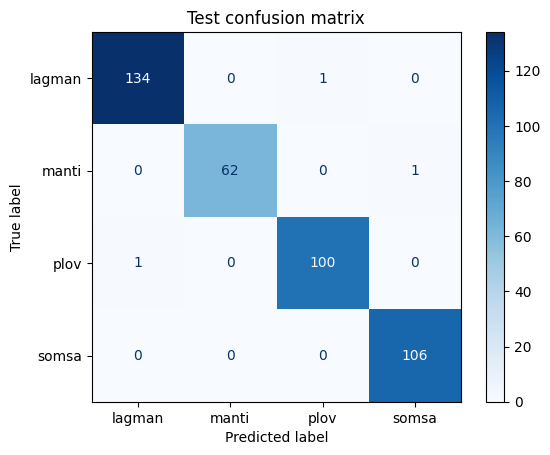

In [9]:
def predict(m, X):
    m.eval()
    with torch.no_grad():
        out = [m(prep(X[i:i + 100])) for i in range(0, len(X), 100)]
    return torch.cat(out).argmax(1).cpu().numpy()

for name, X, y in [("Validation", Xva, yva), ("Test", Xte, yte)]:
    pred, true = predict(model, X), y.cpu().numpy()
    print(f"===== {name} =====")
    print("Accuracy:", round(accuracy_score(true, pred), 4))
    print("Macro F1:", round(f1_score(true, pred, average="macro"), 4))
    print(classification_report(true, pred, target_names=classes, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(true, pred), display_labels=classes).plot(cmap="Blues")
    plt.title(f"{name} confusion matrix")
    plt.show()

3 mistakes out of 405


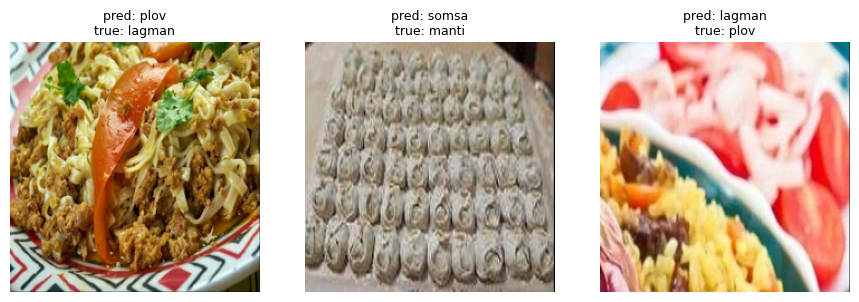

In [10]:
pred, true = predict(model, Xte), yte.cpu().numpy()
wrong = np.where(pred != true)[0]
print(f"{len(wrong)} mistakes out of {len(true)}")

if len(wrong) > 0:
    n = min(len(wrong), 6)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(Xte[i].cpu().permute(1, 2, 0))
        ax.set_title(f"pred: {classes[pred[i]]}\ntrue: {classes[true[i]]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()

## Step 5 : test on 2–3 new images

Saving imgi_32_OIP.webp to imgi_32_OIP.webp


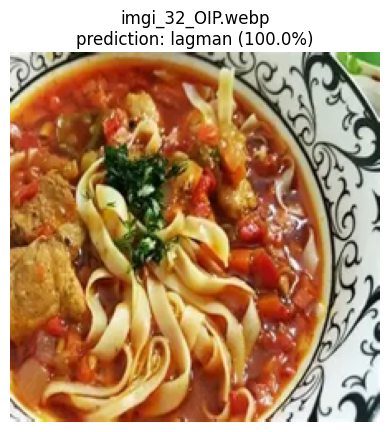

   lagman  1.000
   manti   0.000
   somsa   0.000
   plov    0.000


In [11]:
uploaded = files.upload()   # pick 2–3 images from your computer

model.eval()
for fname in uploaded:
    img = Image.open(fname).convert("RGB").resize((IMG, IMG))
    x = torch.tensor(np.asarray(img)).permute(2, 0, 1).unsqueeze(0).to(device)
    with torch.no_grad():
        p = model(prep(x)).softmax(1)[0].cpu()
    top = p.argsort(descending=True)

    plt.imshow(img); plt.axis("off")
    plt.title(f"{fname}\nprediction: {classes[top[0]]} ({p[top[0]]:.1%})")
    plt.show()
    for i in top:
        print(f"   {classes[i]:7s} {p[i]:.3f}")

Saving imgi_73_OIP.webp to imgi_73_OIP (2).webp


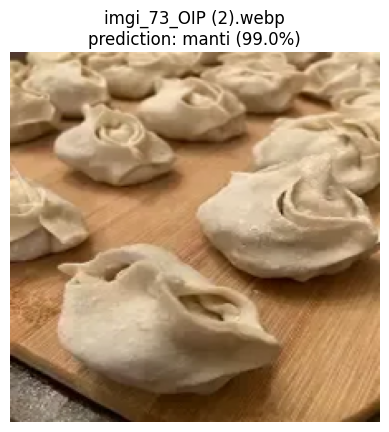

   manti   0.990
   lagman  0.008
   somsa   0.002
   plov    0.001


In [17]:
def check(fname):
    model.eval()
    img = Image.open(fname).convert("RGB").resize((IMG, IMG))
    x = torch.tensor(np.asarray(img)).permute(2, 0, 1).unsqueeze(0).to(device)
    with torch.no_grad():
        p = model(prep(x)).softmax(1)[0].cpu()
    top = p.argsort(descending=True)
    plt.imshow(img); plt.axis("off")
    plt.title(f"{fname}\nprediction: {classes[top[0]]} ({p[top[0]]:.1%})")
    plt.show()
    for i in top:
        print(f"   {classes[i]:7s} {p[i]:.3f}")

uploaded = files.upload()   # select your 2 photos (hold Ctrl to pick both)
for fname in uploaded:
    check(fname)

Saving imgi_34_default.webp to imgi_34_default (1).webp


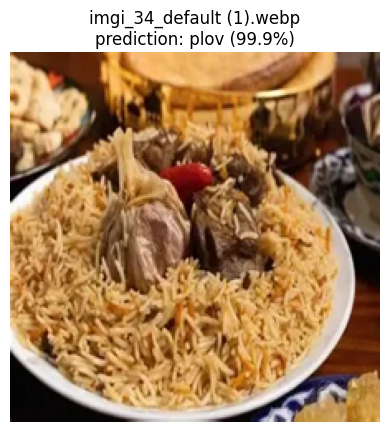

   plov    0.999
   lagman  0.000
   manti   0.000
   somsa   0.000


In [21]:
for fname in files.upload():
    check(fname)

In [24]:
torch.save(model.state_dict(), "/content/drive/MyDrive/uzbek_dishes_resnet18.pt")
print("Model saved")

Model saved


## Conclusion

**Task:** Classify 4 Uzbek dishes — **lagman, manti, plov, somsa** — using transfer learning.

**Data:** Central Asian Food Dataset (CAFD, ISSAI, CC BY-NC 4.0). Used the dataset's own splits:
train 1,932 / val 415 / test 405 images (224×224). The three lagman classes in CAFD
(fried, with soup, without soup) were merged into one `lagman` class.

**Model:** ResNet18 pretrained on ImageNet (timm). The last layer was replaced with
`Linear(512 → 4)` and the **whole model was fine-tuned** (Adam, lr = 3e-4, 10 epochs,
batch 32, random horizontal flip). Inputs normalised with ImageNet mean/std.

### Results

| Set | Accuracy | Macro F1 | Mistakes |
|---|---|---|---|
| Validation | 0.995 | 0.994 | 2 / 415 |
| Test | 0.993 | 0.993 | 3 / 405 |

- Validation accuracy was already **0.973 after the first epoch** — the ImageNet
  features transfer well even to dishes ImageNet has never seen.
- Validation and test scores are almost identical, so the model generalises to unseen data.
- **Plov** was perfect on validation (precision and recall 1.000); **somsa** reached
  recall 1.000 on the test set.
- **Manti** had the lowest recall on both sets (0.985 val, 0.984 test), likely because it is
  the smallest class (294 training images) — but that is only one missed image each time.

### Error analysis (test set)
All 3 mistakes come from unusual or ambiguous images rather than a systematic confusion:
1. **Fried lagman with minced meat → predicted plov:** the grainy meat texture resembles plov.
2. **Raw, uncooked manti in rows on a tray → predicted somsa:** training manti are almost always cooked and served.
3. **Plov photo dominated by tomato-onion salad → predicted lagman:** the dish itself is barely visible.

### New images
3 / 3 new internet images were classified correctly and confidently:
lagman (100.0%), manti (99.0%), plov (99.9%).
Interestingly, the new manti photo shows **raw** manti and was still recognised — so the
test-set mistake above is more about the unusual top-down, tightly packed layout than
about raw manti in general.

### Limitations
- The model always picks one of the 4 classes — it has no "other" option, so a
  non-Uzbek dish would still be forced into one of them.
- The 4 dishes look quite different from each other, which makes the task easier
  than fine-grained classification (the CAFD paper reports 88.7% on all 42 classes).
- Some CAFD images were taken from recipe-video frames, so similar frames could appear
  in different splits; this was not checked and could make the scores slightly optimistic.
- Results come from a single run (seed 0); retraining on GPU gives slightly different numbers.

In [25]:
# half-precision copy for GitHub (25 MB web-upload limit)
sd = {k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()}
torch.save(sd, "uzbek_dishes_fp16.pt")
print("Size (MB):", round(Path("uzbek_dishes_fp16.pt").stat().st_size / 1e6, 1))

# check: does the small model give the same accuracy?
small = timm.create_model("resnet18", pretrained=False, num_classes=4).to(device)
small.load_state_dict(torch.load("uzbek_dishes_fp16.pt"))
print("Original val acc:", round(acc(model, Xva, yva), 4))
print("Small    val acc:", round(acc(small, Xva, yva), 4))

files.download("uzbek_dishes_fp16.pt")

Size (MB): 22.4
Original val acc: 0.9952
Small    val acc: 0.9952


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>